Questo notebook analizza il dataset test_dataset2 costruito nel Notebook01 per capire se è adatto alla costruzione di un sistema di raccomandazione.
In particolare analizza sparsità, distribuzione per categoria e possibili soglie di filtraggio.

## 1-setup

In [1]:
#Se mancano pacchetti, esegui questa cella una sola volta.
%pip install -q "datasets==3.6.0" pandas pyarrow requests tqdm
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import json
import math
import warnings #gestire warnings
import numpy as np 
import pandas as pd
import pyarrow.parquet as pq 
import matplotlib.pyplot as plt 

warnings.filterwarnings("ignore", category=FutureWarning) #nasconde avvisi per avere output meno rumoroso
#impostazioni di pandas
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")  

## 2 percorsi file

In [3]:
#percorsi
CATEGORY="AmazonLike_v2"
DATASET_NAME="test_dataset3"

PROJECT_ROOT=Path(r"C:\Users\arsid\Desktop\Tesi-ecommerce")
PROCESSED_DIR=PROJECT_ROOT/"data"/"processed"/f"{DATASET_NAME}_intersection" #percorso dati notebook01
ANALYSIS_DIR=PROCESSED_DIR/"analysis" #dove salvare risultati notebook02
ANALYSIS_DIR.mkdir(parents=True,exist_ok=True) #la crea se non esiste già

#percorsi dei file prodotti nel notebook01
ITEMS_PATH=PROCESSED_DIR/"items.parquet"
QA_PATH=PROCESSED_DIR/"qa.parquet"
RATINGS_PATH=PROCESSED_DIR/"ratings.parquet"
SUMMARY_PATH=PROCESSED_DIR/"summary.json"
CATEGORY_SUMMARY_PATH=PROCESSED_DIR/"category_summary.csv"

print("Project root:",PROJECT_ROOT)
print("Processed dir:",PROCESSED_DIR)
print("Analysis dir:",ANALYSIS_DIR)


Project root: C:\Users\arsid\Desktop\Tesi-ecommerce
Processed dir: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\test_dataset3_intersection
Analysis dir: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\test_dataset3_intersection\analysis


## 3 lettura dati parquet

In [4]:
#lettura dei metadata dei parquet
def parquet_info(path: Path)->dict:
    pf=pq.ParquetFile(path)
    return{
        "file":path.name,
        "rows":pf.metadata.num_rows,
        "row_groups":pf.metadata.num_row_groups,
        "columns": len(pf.schema_arrow.names),
        "column_names": ", ".join(pf.schema_arrow.names),
    }

parquet_infos=pd.DataFrame([
    parquet_info(ITEMS_PATH),
    parquet_info(QA_PATH),
    parquet_info(RATINGS_PATH),
])

parquet_infos

,file,rows,row_groups,columns,column_names
0,items.parquet,11451,1,16,"parent_asin, source_category, hf_category, qa_slug, category_group, title, category, avg_rating, num_ratings, price,..."
1,qa.parquet,94100,1,12,"qa_id, parent_asin, source_category, hf_category, qa_slug, category_group, question, answer, questionType, answerTyp..."
2,ratings.parquet,125029,1,12,"user_id, parent_asin, source_category, hf_category, qa_slug, category_group, asin, rating, timestamp, verified_purch..."


## 4 caricamento dei dati

In [5]:
#caricamento dei dati
def parquet_columns(path: Path)-> list[str]: #funzione che restituisce i nomi delle colonne
    return pq.ParquetFile(path).schema_arrow.names

def columns_keep(path: Path, wanted: list[str])-> list[str]: #funzione che tiene solo le colonne richieste
    available=set(parquet_columns(path))
    return [col for col in wanted if col in available]

items_df=pd.read_parquet(ITEMS_PATH)
qa_df=pd.read_parquet(QA_PATH)

wanted_rating_columns=[
    "user_id","parent_asin","source_category","hf_category","category_group","asin","rating","timestamp","verified_purchase",
    "review_title","review_text",#se presenti le colonne testuali, in base a cosa si è scelto nel notebook 01
]

rating_columns=columns_keep(RATINGS_PATH,wanted_rating_columns)
ratings_df=pd.read_parquet(RATINGS_PATH,columns=rating_columns)

print("items_df:", items_df.shape)
print("qa_df:", qa_df.shape)
print("ratings_df:", ratings_df.shape)
print("Colonne rating caricate:", rating_columns)

items_df: (11451, 16)
qa_df: (94100, 12)
ratings_df: (125029, 11)
Colonne rating caricate: ['user_id', 'parent_asin', 'source_category', 'hf_category', 'category_group', 'asin', 'rating', 'timestamp', 'verified_purchase', 'review_title', 'review_text']


In [6]:
display(items_df.head(3))
display(qa_df.head(3))
display(ratings_df.head(3))

,parent_asin,source_category,hf_category,qa_slug,category_group,title,category,avg_rating,num_ratings,price,store,features_json,description_json,categories_json,details_json,image_url
0,B00CFGZAT8,Electronics,Electronics,Electronics,tech,"Dock Audio Extender Adapter Converter Cable for iPod iPhone 4 4S iPhone 5 5S iPad, Samsung & Other Smart Phones",Portable Audio & Accessories,3.600000,45,NaN,iteck,[],[],"[""Electronics"", ""Computers & Accessories"", ""Tablet Accessories"", ""Chargers & Adapters""]","{""Brand Name"": ""iTeck"", ""Item Weight"": ""0.8 ounces"", ""Package Dimensions"": ""6 x 4 x 0.3 inches; 0.8 Ounces"", ""Item m...",NaN
1,B00BGFTSGU,Electronics,Electronics,Electronics,tech,GGS Swivi HD DSLR LCD Universal Foldable Viewfinder Version II with 3.0X Magnification,Camera & Photo,3.700000,52,149.000000,Swivi,[],[],"[""Electronics"", ""Camera & Photo"", ""Accessories"", ""Viewfinders""]","{""Product Dimensions"": ""3.8 x 4.3 x 6.9 inches"", ""Item Weight"": ""0.705 ounces"", ""Item model number"": ""Swivi Viewfind...",NaN
2,B00AZOIG9I,Electronics,Electronics,Electronics,tech,BM Premium 2-Pack of NP-85 Batteries and Charger Kit for FujiFilm FinePix S1 SL240 SL260 SL280 SL300 SL305 SL1000 Di...,Camera & Photo,4.700000,345,22.990000,BM Premium,"[""NP85 Li-ion Battery for FujiFilm FinePix SL240 SL260 SL280 SL300 SL305 SL1000 Digital Camera"", ""Battery Specificat...","[""Bring your digital camera back to life with a new battery. Make sure you never miss another once-in-a-lifetime mom...","[""Electronics"", ""Camera & Photo"", ""Accessories"", ""Batteries & Chargers"", ""Batteries"", ""Camera Batteries""]","{""Package Dimensions"": ""6.46 x 3.94 x 1.85 inches"", ""Item Weight"": ""6.7 ounces"", ""Item model number"": ""NP85"", ""Batte...",NaN


,qa_id,parent_asin,source_category,hf_category,qa_slug,category_group,question,answer,questionType,answerType,answerTime,unixTime
0,84,1400501741,Electronics,Electronics,Electronics,tech,Can I port my Kindle books to this platform?,You just need to download the Kindle app from the Google Play store. Then you can download your books.,yes/no,?,"Apr 8, 2014","1,396,940,400.000000"
1,85,1400501741,Electronics,Electronics,Electronics,tech,Why is it 179.99? Everywhere else is 269.99...What does shrink wrapped mean? What make it $90 cheaper here?,Its 179 on the Barnes and Noble web site as well as Best Buy.,open-ended,NaN,"Feb 8, 2014","1,391,846,400.000000"
2,86,1400501741,Electronics,Electronics,Electronics,tech,"Can you use Word2010 and OneNote2010 on the Nook HD+ ? If so do I need any kind of adapters etc, apps or new softwar...","Word and OneNote have Android versions, however they are designed for mobile phone use so the screen might adjust we...",open-ended,NaN,"Jul 23, 2013","1,374,562,800.000000"


,user_id,parent_asin,source_category,hf_category,category_group,asin,rating,timestamp,verified_purchase,review_title,review_text
0,AFTC6ZR5IKNRDG5JCPVNVMU3XV2Q,B001FWYGJS,Electronics,Electronics,tech,B001FWYGJS,4.000000,1427592277000,True,good and cheap,Had for about a month now. Still running strong and keeping my twc ultimate internet on all 8 of my houses devices. ...
1,AEFKF6R2GUSK2AWPSWRR4ZO36JVQ,B0092TGP4A,Electronics,Electronics,tech,B0092TGP4A,4.000000,1364085263000,True,HDE VGA RCA adapter,sometimes in my room I watch movies on my computer: this adapter allows me to watch on a bigger screen: since the tv...
2,AEFKF6R2GUSK2AWPSWRR4ZO36JVQ,B000SJ2TJ8,Electronics,Electronics,tech,B000SJ2TJ8,3.000000,1360233955000,True,6ft VGA to RCA,"this was a perfectly good item, but I could not use it: I ordered the wrong cable. . .It came on time as promised. I..."


## 5 controlli di coerenza

In [7]:
#controlli generali di coerenza
def pct(numerator, denominator): #funzione che useremo anche dopo per calcolare la percentuale
    if denominator == 0:
        return np.nan
    return numerator/denominator *100

items_set=set(items_df["parent_asin"].dropna()) #insieme parentasin nei metadati, droppando valori nulli
ratings_items_set=set(ratings_df["parent_asin"].dropna()) #insieme parentasin dei rating
qa_items_set=set(qa_df["parent_asin"].dropna()) #insieme parentasin qa
#dizionario con statistiche generali del dataset
basic_stats={
    "num_product_items": items_df["parent_asin"].nunique(), #conta quanti prodotti unici nella tabella items
    "num_rating_rows": len(ratings_df), #conta quante righe di rating presenti
    "num_users":ratings_df["user_id"].nunique(dropna=True), #quanti utenti unici compaiono nei rating
    "num_products_with_ratings": ratings_df["parent_asin"].nunique(dropna=True), #quanti prodotti distinti hanno almeno un rating
    "num_qa_rows":len(qa_df), #quante righe di domande/risposte presenti
    "num_products_with_qa": qa_df["parent_asin"].nunique(dropna=True), #quanti prodotti distinti hanno almeno una domanda/risposta
    "items_parent_asin_unique": bool(items_df["parent_asin"].is_unique), #controlla se parent_asin è unico nella tabella items
    "ratings_products_all_in_items": ratings_items_set.issubset(items_set), #verifica se tutti i prodotti nei rating sono presenti anche nei metadati items
    "qa_products_all_in_items": qa_items_set.issubset(items_set), #controlla se tutti prodotti qa sono presenti anche nei metadati items
    "items_with_rating_pct": pct(len(items_set & ratings_items_set), len(items_set)), #calcola percentuale di prodotti items che hanno almeno un rating
    "items_with_qa_pct": pct(len(items_set & qa_items_set), len(items_set)), #calcola percentuale di prodotti items che hanno almeno una riga QA
}

basic_stats_df=pd.DataFrame.from_dict(basic_stats, orient="index", columns=["value"]) #converte dizionario delle stats generali in tabella pandas
display(basic_stats_df)

basic_stats_df.to_csv(ANALYSIS_DIR/"notebook02_basic_stats.csv")

,value
num_product_items,11451
num_rating_rows,125029
num_users,87232
num_products_with_ratings,11451
num_qa_rows,94100
num_products_with_qa,11451
items_parent_asin_unique,True
ratings_products_all_in_items,True
qa_products_all_in_items,True
items_with_rating_pct,100.000000


In [8]:
#analisi per categoria del dataset multi-categoria
#serve a controllare se una categoria domina troppo o se alcune categorie restano piccole
category_items_df=items_df.groupby("source_category").agg( #raggruppa items finali per categoria
    products=("parent_asin","nunique"), #n prodotti
    avg_metadata_rating=("avg_rating","mean"), #media rating dai metadati
    avg_metadata_num_ratings=("num_ratings","mean"), #per ogni categoria quanti rating medi per prodotti dai metadati
).reset_index()

category_ratings_df=ratings_df.groupby("source_category").agg(  #analisi rating per categoria
    rating_rows=("rating","size"), #n righe rating
    users=("user_id","nunique"), #n utenit che hanno lasciato rating
    products_with_ratings=("parent_asin","nunique"), #prodotti con almeno un rating
    avg_rating=("rating","mean"), #rating medio effettivo dalle righe di ratingsdf
).reset_index()

category_qa_df=qa_df.groupby("source_category").agg( #qa per categ
    qa_rows=("parent_asin","size"), #n righe
    products_with_qa=("parent_asin","nunique"), #n prodotti
).reset_index()
#unisce le tre tabelle per categoria
category_profile_df=category_items_df.merge(category_ratings_df,on="source_category",how="outer")
category_profile_df=category_profile_df.merge(category_qa_df,on="source_category",how="outer")

category_summary_from_nb01_df=pd.read_csv(CATEGORY_SUMMARY_PATH)
print("Riepilogo prodotto dal Notebook01")
display(category_summary_from_nb01_df)

print("Profilo categorie dal dataset caricato")
display(category_profile_df.sort_values("products",ascending=False))
category_profile_df.to_csv(ANALYSIS_DIR/"notebook02_category_profile.csv",index=False)


Riepilogo prodotto dal Notebook01


,source_category,hf_category,qa_slug,category_group,qa_rows,qa_products,metadata_rows,items_qa_metadata,duplicate_items_skipped,qa_rows_after_metadata,qa_products_after_metadata,reviews_scanned,ratings_saved,final_products_qa_metadata_rating
0,Electronics,Electronics,Electronics,tech,314263,39371,400000,6142,0,48316,6142,1200000,30249,4153
1,Video Games,Video_Games,Video_Games,tech,13307,1188,116964,600,0,6536,600,400000,24128,580
2,Software,Software,Software,tech,10636,1191,85068,600,0,5371,600,250000,4809,489
3,Office Products,Office_Products,Office_Products,office,43608,5681,357577,1500,0,11441,1500,600000,14912,1189
4,Appliances,Appliances,Appliances,home,9011,1153,78147,600,0,4619,600,250000,13323,533
5,Musical Instruments,Musical_Instruments,Musical_Instruments,music,23322,3002,136734,1200,0,8921,1200,400000,14078,1067
6,Arts Crafts and Sewing,Arts_Crafts_and_Sewing,Arts_Crafts_and_Sewing,crafts,21262,2944,488101,1000,0,7181,1000,500000,7554,785
7,Automotive,Automotive,Automotive,automotive,89923,12536,106545,500,0,3459,500,250000,690,234
8,Baby Products,Baby_Products,Baby,baby,28933,3783,59199,500,0,3882,500,250000,4295,363
9,Grocery and Gourmet Food,Grocery_and_Gourmet_Food,Grocery_and_Gourmet_Food,grocery,19538,3017,150000,333,0,2162,333,250000,868,200


Profilo categorie dal dataset caricato


,source_category,products,avg_metadata_rating,avg_metadata_num_ratings,rating_rows,users,products_with_ratings,avg_rating,qa_rows,products_with_qa
4,Electronics,4153,3.917192,492.530460,30249,22543,4153,4.144468,34634,4153
8,Office Products,1189,3.981581,635.883936,14912,13089,1189,4.250469,9514,1189
7,Musical Instruments,1067,4.023055,262.114339,14078,12334,1067,4.275039,8185,1067
1,Arts Crafts and Sewing,785,4.239490,565.189809,7554,6363,785,4.403230,5846,785
15,Video Games,580,4.069138,"1,093.744828",24128,19385,580,4.318675,6377,580
0,Appliances,533,3.979737,643.579737,13323,12600,533,4.415597,4241,533
11,Software,489,3.551738,222.490798,4809,4291,489,3.801206,4594,489
14,Toys and Games,481,4.348857,"1,567.438669",3699,3330,481,4.505542,3602,481
3,Baby Products,363,4.123140,775.088154,4295,3755,363,4.316414,2941,363
13,Tools and Home Improvement,320,4.116562,728.018750,1317,1229,320,4.298405,2518,320


## 6 controllo qualità dei dati

In [9]:
#ora bisogna controllare la qualità di questi dati
important_columns={ #dizionario con colonne importanti da controllare
    "items":["parent_asin","source_category","title","category"],
    "qa":["parent_asin","source_category","question","answer"],
    "ratings":["user_id","parent_asin","source_category","rating"],
}
null_rows=[]
#scorriamo le tabelle e colonne da controllare
for df_name, cols in important_columns.items():
    df={"items":items_df, "qa":qa_df, "ratings":ratings_df}[df_name]
    for col in cols:
        if col in  df.columns:
            null_rows.append({
                "table":df_name,
                "column":col,
                "null_count":int(df[col].isna().sum()), #conta quanti valori nulli presenti nella colonna
                "null_pct": pct(int(df[col].isna().sum()), len(df)), #conta la percentuale di valori nulli nella colonna
            })

nulls_df=pd.DataFrame(null_rows)
nulls_df


,table,column,null_count,null_pct
0,items,parent_asin,0,0.000000
1,items,source_category,0,0.000000
2,items,title,0,0.000000
3,items,category,0,0.000000
4,qa,parent_asin,0,0.000000
5,qa,source_category,0,0.000000
6,qa,question,0,0.000000
7,qa,answer,0,0.000000
8,ratings,user_id,0,0.000000
9,ratings,parent_asin,0,0.000000


In [10]:
#vediamo se ci sono rating nulli
invalid_rating_mask= ratings_df["rating"].isna() | ~ratings_df["rating"].between(1,5)
invalid_ratings=ratings_df.loc[invalid_rating_mask]
print("Rating nulli o fuori scala:", len(invalid_ratings))
if len(invalid_ratings)>0:
    display(invalid_ratings.head()) 


Rating nulli o fuori scala: 0


In [11]:
#calcoliamo distribuzione dei voti
rating_dist=(
    ratings_df["rating"].value_counts(dropna=False).sort_index().rename_axis("rating").reset_index(name="count")
)
rating_dist["pct"]=rating_dist["count"]/len(ratings_df)*100 #percentuale di ogni voto sul tot
rating_dist

,rating,count,pct
0,1.000000,9668,7.732606
1,2.000000,5402,4.320598
2,3.000000,9087,7.267914
3,4.000000,19092,15.270057
4,5.000000,81780,65.408825


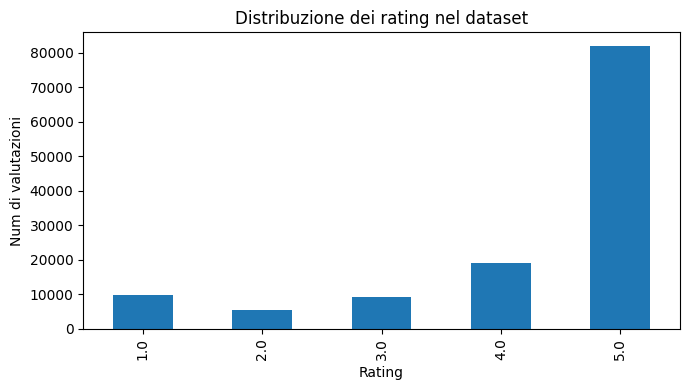

In [12]:
#schema dei dati visti sopra sui rating
plt.figure(figsize=(7,4))
rating_dist.dropna(subset=["rating"]).plot(
    x="rating",y="count",kind="bar",legend=False,ax=plt.gca()
)
plt.title("Distribuzione dei rating nel dataset")
plt.xlabel("Rating")
plt.ylabel("Num di valutazioni")
plt.tight_layout()
plt.show()

In [13]:
#funzione per capire se timestamp sono in sec o millisec
def timestamp_un(series:pd.Series)->str | None:
    values=pd.to_numeric(series.dropna(), errors="coerce").dropna() #converte timestamp in numeri
    if values.empty:
        return None
    median_value=values.median()
    if median_value>1e12: #se compatibile con millisecondi
        return "ms"
    if median_value>1e9: #se compatibile con secondi
        return "s"
    return None

timestamp_unit=timestamp_un(ratings_df["timestamp"]) #stima l'unità del timestamp
print("Unità stimata del timestamp: ",timestamp_unit)


ratings_df["datetime"]=pd.to_datetime(
    ratings_df["timestamp"], unit=timestamp_unit,errors="coerce" #passa a pandas la colonna timestamp da convertire
)
print("data minima: ",ratings_df["datetime"].min())
print("data massima: ",ratings_df["datetime"].max())
display(ratings_df[["timestamp","datetime"]].head())

Unità stimata del timestamp:  ms
data minima:  2000-10-10 20:32:59
data massima:  2023-03-21 21:11:50.047000


,timestamp,datetime
0,1427592277000,2015-03-29 01:24:37.000
1,1364085263000,2013-03-24 00:34:23.000
2,1360233955000,2013-02-07 10:45:55.000
3,1590503106817,2020-05-26 14:25:06.817
4,1384872193000,2013-11-19 14:43:13.000


In [14]:
#controlliamo duplicati userid+parentasin
pair_columns=["user_id","parent_asin"]
duplicate_mask=ratings_df.duplicated(pair_columns,keep=False)#crea maschera che marca tutte le righe appartenenti a coppie utente-prodotto duplicate
num_duplicate_rows=int(duplicate_mask.sum()) #conta righe duplicate
num_duplicate_pairs=int(ratings_df.loc[duplicate_mask,pair_columns].drop_duplicates().shape[0]) #conta coppie duplicate
print("Righe coinvolte in duplicati user_id+parent_asin:", num_duplicate_rows)
print("Coppie duplicate distinte:", num_duplicate_pairs)

if num_duplicate_rows>0:
    display( #seleziona solo righe duplicate, e le ordina
        ratings_df.loc[duplicate_mask].sort_values(pair_columns+(["timestamp"] if "timestamp" in ratings_df.columns else [])).head(10)
    )


Righe coinvolte in duplicati user_id+parent_asin: 704
Coppie duplicate distinte: 351


,user_id,parent_asin,source_category,hf_category,category_group,asin,rating,timestamp,verified_purchase,review_title,review_text,datetime
76881,AE2B7AQSZED3AYMTREETFR4JEVRQ,B0089VAAF2,Appliances,Appliances,home,B0089VAAF2,5.000000,1430220973000,True,Five Stars,"Fit perfect and works great, really fast delivery",2015-04-28 11:36:13
76884,AE2B7AQSZED3AYMTREETFR4JEVRQ,B0089VAAF2,Appliances,Appliances,home,B0089VAAF2,5.000000,1430220973000,True,Five Stars,"Fit perfect and works great, really fast delivery",2015-04-28 11:36:13
76880,AE2B7AQSZED3AYMTREETFR4JEVRQ,B0089VAAIY,Appliances,Appliances,home,B0089VAAIY,5.000000,1481061241000,True,Five Stars,nice fit for our Samsung refrig,2016-12-06 21:54:01
76883,AE2B7AQSZED3AYMTREETFR4JEVRQ,B0089VAAIY,Appliances,Appliances,home,B0089VAAIY,5.000000,1481061241000,True,Five Stars,nice fit for our Samsung refrig,2016-12-06 21:54:01
10953,AE2YT5NODO5H7VNHTO6CYQAE4VQA,B000IHGJ50,Electronics,Electronics,tech,B000IHGJ50,5.000000,1416511672000,True,Old timey goodness,Bought an old version on purpose ... wanted it to be cheap (if my sixth grader loses it) plus the sheer size & simpl...,2014-11-20 19:27:52
10957,AE2YT5NODO5H7VNHTO6CYQAE4VQA,B000IHGJ50,Electronics,Electronics,tech,B000IHGJ50,5.000000,1416511672000,True,Old timey goodness,Bought an old version on purpose ... wanted it to be cheap (if my sixth grader loses it) plus the sheer size & simpl...,2014-11-20 19:27:52
10954,AE2YT5NODO5H7VNHTO6CYQAE4VQA,B003N3GRCQ,Electronics,Electronics,tech,B003N3GRCQ,5.000000,1357281412000,True,Nice length for my car,The iPhone dock cord that came with my car is very short ... this one is only 2' and provides a great extension with...,2013-01-04 06:36:52
10958,AE2YT5NODO5H7VNHTO6CYQAE4VQA,B003N3GRCQ,Electronics,Electronics,tech,B003N3GRCQ,5.000000,1357281412000,True,Nice length for my car,The iPhone dock cord that came with my car is very short ... this one is only 2' and provides a great extension with...,2013-01-04 06:36:52
28399,AE374LE7XANMIUY5B4FENPQRFGLA,B007PLL4CK,Electronics,Electronics,tech,B007PLL4CK,2.000000,1443205828000,True,WRong configuration,"Still not the right item for my set up, but I could not tell by the photo on the website until I received it.",2015-09-25 18:30:28
28402,AE374LE7XANMIUY5B4FENPQRFGLA,B007PLL4CK,Electronics,Electronics,tech,B007PLL4CK,2.000000,1443205828000,True,WRong configuration,"Still not the right item for my set up, but I could not tell by the photo on the website until I received it.",2015-09-25 18:30:28


,year,count,pct
0,2000,1,0.000800
1,2001,7,0.005599
2,2002,22,0.017596
3,2003,21,0.016796
4,2004,39,0.031193
5,2005,81,0.064785
6,2006,205,0.163962
7,2007,484,0.387110
8,2008,703,0.562270
9,2009,1049,0.839005


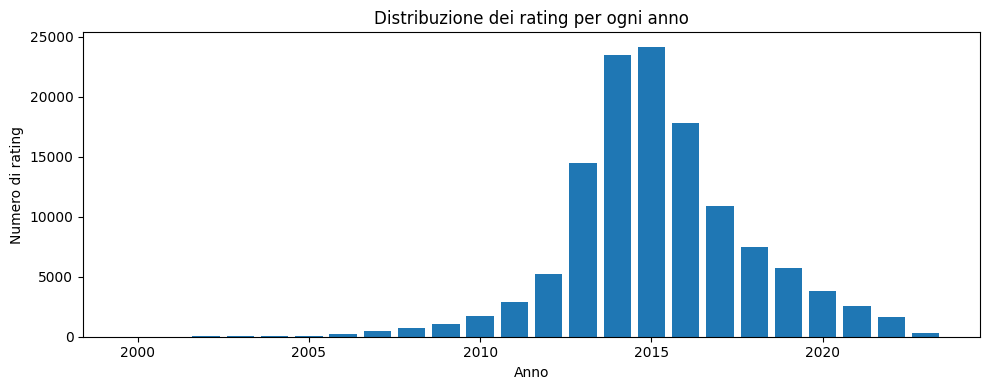

In [15]:
#andiamo ad analizzare le valutazioni per ogni anno
if "datetime" in ratings_df.columns:
    ratings_each_year =(
        ratings_df["datetime"]
        .dt.year
        .value_counts()
        .sort_index()
        .rename_axis("year")
        .reset_index(name="count")
    )

    ratings_each_year["pct"]=ratings_each_year["count"]/len(ratings_df)*100
    display(ratings_each_year)
    plt.figure(figsize=(10,4))
    plt.bar(ratings_each_year["year"], ratings_each_year["count"])
    plt.title("Distribuzione dei rating per ogni anno")
    plt.xlabel("Anno")
    plt.ylabel("Numero di rating")
    plt.tight_layout()
    plt.show()

## 7 costruzione tabella nuova pulita

Costruiamo la tabella sistemata:
rimuoviamo le righe non valide, duplicate.

In [16]:
def build_int_table(ratings: pd.DataFrame) ->pd.DataFrame: #funzione per pulire e togliere duplicati
    base=ratings.copy() #crea copia
    base=base.dropna(subset=["user_id","parent_asin","rating"]) #rimuove righe senza utente, prodotto, rating
    base=base[base["rating"].between(1,5)].copy() #mantiene rating fra 1 e 5
    base=base.sort_values(["user_id","parent_asin","timestamp"]) #ordina valutazioni per utente, prodotto e timestamp
    interactions=base.drop_duplicates(["user_id","parent_asin"],keep="last").copy()#per ogni coppia tiene solo l'ultima
    return interactions.reset_index(drop=True) #restituisce interazioni pulite con indice ricreato da zero

interactions_df=build_int_table(ratings_df) #applica la funzione ai rating

print("Righe rating originali: ",f"{len(ratings_df):,}")
print("Interazioni dopo la pulizia:",f"{len(interactions_df):,}")
print("Righe rimosse nella pulizia:",f"{len(ratings_df)-len(interactions_df):,}")
display(interactions_df.head())

Righe rating originali:  125,029
Interazioni dopo la pulizia: 124,676
Righe rimosse nella pulizia: 353


,user_id,parent_asin,source_category,hf_category,category_group,asin,rating,timestamp,verified_purchase,review_title,review_text,datetime
0,AE22236AFRRSMQIKGG7TPTB75QEA,B002BS47JE,Video Games,Video_Games,tech,B002BS47JE,5.000000,1275247369000,False,Takes Wii Fit to the next level,This game made Wii Fit so much better. Its a must have. The new games are awesome. And the ability to have workou...,2010-05-30 19:22:49.000
1,AE2232IXUSRI4JCOAJTB7V57NDYQ,B0040FJ27S,Musical Instruments,Musical_Instruments,music,B0040FJ27S,4.000000,1450121060000,True,Four Stars,Fun kit for the price,2015-12-14 19:24:20.000
2,AE223HSAZU6TUGSD7F47WOADLS2Q,B00IAVDOS6,Video Games,Video_Games,tech,B00IAVDOS6,1.000000,1515525400270,True,... a headphone jack in it already this thing is useless. DOES NOT MAKE APPLE HEADPHONES WORK WITH MIC ...,If your controller has a headphone jack in it already this thing is useless. DOES NOT MAKE APPLE HEADPHONES WORK WIT...,2018-01-09 19:16:40.270
3,AE223SBXB2PFTMOITN4V53TLSFSA,B001DHLGOS,Appliances,Appliances,home,B001DHLGOS,5.000000,1466628133000,True,Five Stars,worked good and was a direct replacement,2016-06-22 20:42:13.000
4,AE223SBXB2PFTMOITN4V53TLSFSA,B00I5LMSE2,Video Games,Video_Games,tech,B00I5LMSE2,4.000000,1466628706000,True,Four Stars,kids loved it,2016-06-22 20:51:46.000


## 8 analisi degli utenti

Analizziamo gli utenti, quante interazioni ha ciascun utente

In [17]:

def analyze_quantilies(counts: pd.Series, name: str)-> pd.DataFrame: #funzione per riassumere conteggi
    quantiles=counts.quantile([0.25,0.50,0.75,0.90,0.95,0.99]).to_dict()
    data={
        "entity":name,
        "num_entities":counts.shape[0],
        "mean":counts.mean(),
        "median":counts.median(),
        "min":counts.min(),
        "p25":quantiles.get(0.25),
        "p75":quantiles.get(0.75),
        "p90":quantiles.get(0.90),
        "p95":quantiles.get(0.95),
        "p99":quantiles.get(0.99),
        "max":counts.max(),
    }
    return pd.DataFrame([data])

user_counts=interactions_df["user_id"].value_counts()
user_summary=analyze_quantilies(user_counts, "users")
user_summary

,entity,num_entities,mean,median,min,p25,p75,p90,p95,p99,max
0,users,87232,1.429246,1.000000,1,1.000000,1.000000,2.000000,3.000000,6.000000,49


In [18]:
user_thresholds=[1,2,3,4,5,6,7,8,9,10,20,50] #soglie da testare minime di interazione per ogni utente
rows=[]

for t in user_thresholds:
    valid_users=user_counts[user_counts>=t].index #.index prende solo identificativi degli utenti rimasti
    filtered=interactions_df[interactions_df["user_id"].isin(valid_users)] #filtriamo tabella, tenendo solo utenti validi che rispettano la soglia di interazioni

    rows.append({
        "min_interactions":t,
        "num_users":filtered["user_id"].nunique(), #num utenti unici rimasti
        "num_products":filtered["parent_asin"].nunique(), #num prodotti unici rimasti
        "num_interactions":len(filtered), #num interazioni rimaste
        "percentage_users":filtered["user_id"].nunique()/interactions_df["user_id"].nunique()*100,
        "percentage_interactions":len(filtered)/len(interactions_df)*100
    })

user_threshold_table=pd.DataFrame(rows)
user_threshold_table

,min_interactions,num_users,num_products,num_interactions,percentage_users,percentage_interactions
0,1,87232,11451,124676,100.000000,100.000000
1,2,20756,9610,58200,23.794021,46.680997
2,3,7837,7808,32362,8.984088,25.956880
3,4,3645,6278,19786,4.178512,15.869935
4,5,1920,5086,12886,2.201027,10.335590
5,6,1144,4149,9006,1.311445,7.223523
6,7,665,3281,6132,0.762335,4.918348
7,8,403,2603,4298,0.461986,3.447335
8,9,256,2101,3122,0.293470,2.504091
9,10,182,1766,2456,0.208639,1.969906


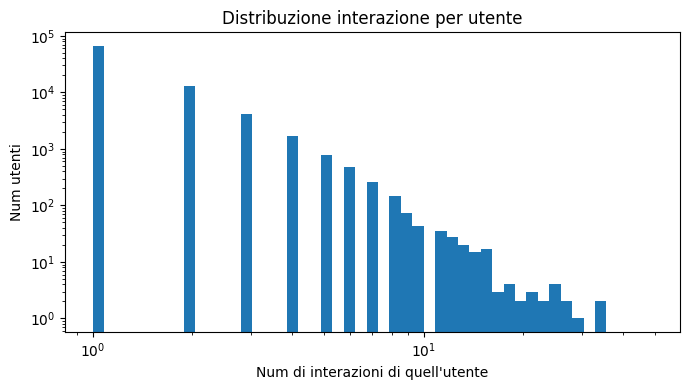

In [19]:
plt.figure(figsize=(7,4))
counts=user_counts[user_counts>0]
#crea 50 intervalli su scala logaritmica tra 10^0=1 e max num di interazioni=10^2=100 circa (in realtà 98)
#essendo molto sbilanciata, tanti utenti hanno poche interazioni, pochi utenti ne hanno molte.super
spaces=np.logspace(0,np.log10(counts.max()),50) if counts.max()>1 else 1 
plt.hist(counts,bins=spaces)
plt.xscale("log")
plt.yscale("log")
plt.title("Distribuzione interazione per utente")
plt.xlabel("Num di interazioni di quell'utente")
plt.ylabel("Num utenti")
plt.tight_layout()
plt.show()

## 9 analisi dei prodotti
vogliamo evitare prodotti con pochissimi rating, ma anche evitare filtri troppo aggressivi

In [20]:
item_counts=interactions_df["parent_asin"].value_counts() #contiamo quante interazioni ha ogni prodotto
item_summary=analyze_quantilies(item_counts, "products") #riepilogo della distribuzione
item_summary

,entity,num_entities,mean,median,min,p25,p75,p90,p95,p99,max
0,products,11451,10.887783,3.000000,1,1.000000,8.000000,21.000000,38.000000,113.000000,3558


In [21]:
#soglie di thresholds da testare
item_thresholds=[1,2,3,4,5,6,7,8,9,10,20,50,100]
rows=[]
for t in item_thresholds:
    valid_items=item_counts[item_counts>=t].index
    filtered=interactions_df[interactions_df["parent_asin"].isin(valid_items)]
    rows.append({ #aggiungiamo dizionario con le statistiche sulla soglia corrente
        "min_product_interactions":t,
        "num_users":filtered["user_id"].nunique(),
        "num_products_remaining":filtered["parent_asin"].nunique(),
        "num_interactions":len(filtered),
        "percentage_users":filtered["user_id"].nunique()/interactions_df["user_id"].nunique()*100,
        "percentage_products":filtered["parent_asin"].nunique()/interactions_df["parent_asin"].nunique()*100,
        "percentage_interactions":len(filtered)/len(interactions_df)*100
    })

item_thresholds_table=pd.DataFrame(rows)
item_thresholds_table

,min_product_interactions,num_users,num_products_remaining,num_interactions,percentage_users,percentage_products,percentage_interactions
0,1,87232,11451,124676,100.000000,100.000000,100.000000
1,2,85956,8526,121751,98.537234,74.456379,97.653919
2,3,84348,6765,118229,96.693874,59.077810,94.828997
3,4,82773,5643,114863,94.888344,49.279539,92.129199
4,5,80994,4737,111239,92.848955,41.367566,89.222465
5,6,79394,4108,108094,91.014765,35.874596,86.699926
6,7,77835,3597,105028,89.227577,31.412104,84.240752
7,8,76423,3197,102228,87.608905,27.918959,81.994931
8,9,74961,2852,99468,85.932915,24.906122,79.781193
9,10,73602,2571,96939,84.375000,22.452188,77.752735


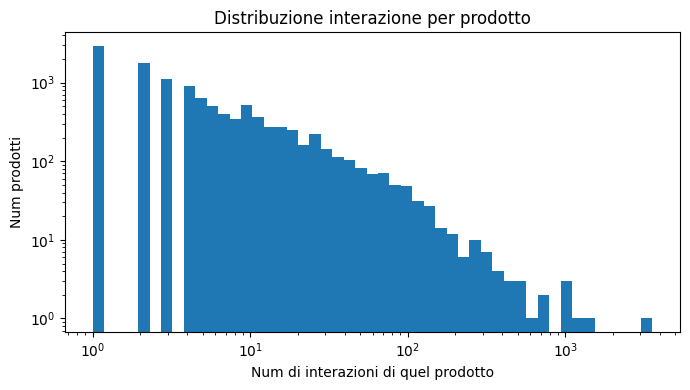

In [22]:
plt.figure(figsize=(7,4))
counts=item_counts[item_counts>0]
spaces=np.logspace(0,np.log10(counts.max()),50) if counts.max()>1 else 1 
plt.hist(counts,bins=spaces)
plt.xscale("log")
plt.yscale("log")
plt.title("Distribuzione interazione per prodotto")
plt.xlabel("Num di interazioni di quel prodotto")
plt.ylabel("Num prodotti")
plt.tight_layout()
plt.show()

## 10 analisi QA per prodotto
inizialmente potrebbe non essere aggiunto, ma è utile vedere ora quante domande/risposte sono associate ai prodotti

In [23]:
qa_counts=qa_df["parent_asin"].value_counts() #conta quante righe associate a ciascun prodotto
total_products=items_df["parent_asin"].nunique() #calcola n tot di prodotti nel catalogo

products_with_qa=qa_counts.shape[0] #num prodotti con almeno una riga qa
total_qa_rows=len(qa_df)

qa_overview=pd.DataFrame([{
    "tot_products":total_products,#num tot di prodotti
    "products_with_qa":products_with_qa,
    "percentage_with_qa":products_with_qa/total_products*100,
    "total_qa_rows":total_qa_rows,
    "mean-qa_perproducts":qa_counts.mean(),
    "median-qa_perproducts":qa_counts.median(),
    "max-qa_perproduct":qa_counts.max()
}])
qa_summary=analyze_quantilies(qa_counts, "products_with_qa")
display(qa_overview)
display(qa_summary)

,tot_products,products_with_qa,percentage_with_qa,total_qa_rows,mean-qa_perproducts,median-qa_perproducts,max-qa_perproduct
0,11451,11451,100.000000,94100,8.217623,10.000000,60


,entity,num_entities,mean,median,min,p25,p75,p90,p95,p99,max
0,products_with_qa,11451,8.217623,10.000000,1,6.000000,10.000000,10.000000,10.000000,20.000000,60


## 11 Profilo prodotti rating + qa + metadati
creiamo una vista sintetica per analisi

In [24]:
profile_col=[
    col for col in  ["parent_asin","source_category","category_group","title","category","avg_rating","num_ratings","price","store"] #scorre colonne candidate
    if col in items_df.columns #list comprehension, crea lista con colonne che esistono davvero dentro dentro l'altra lista
]

item_profile=items_df[profile_col].copy()#crea tab con solo quelle colonne
item_profile=item_profile.merge(
    item_counts.rename("interaction_count"), #rinomina conteggi dei rating
    left_on="parent_asin",  #merge usa parentasin come chiave nel dataframe di sx
    right_index=True, #merge usa indice della serie di destra come chiave
    how="left", #left join per mantenere tutti i prodotti anche se non hanno quel conteggio
)

item_profile=item_profile.merge(
    qa_counts.rename("qa_count"),
    left_on="parent_asin",
    right_index=True,
    how="left",
)
item_profile["interaction_count"] =item_profile["interaction_count"].fillna(0).astype(int) #sostituisce mancanti con 0 e converte a interi
item_profile["qa_count"]= item_profile["qa_count"].fillna(0).astype(int) #sostituisce mancanti con 0 e converte a interi
item_profile.sort_values("interaction_count",ascending=False).head(20) #mostra ordinati dal piu interagito al meno

,parent_asin,source_category,category_group,title,category,avg_rating,num_ratings,price,store,interaction_count,qa_count
4228,B004RMK57U,Video Games,tech,Playstation Plus: 3 Month Membership [Digital Code],Video Games,4.800000,20592,NaN,PlayStation,3558,30
7769,B0040FJ27S,Musical Instruments,music,"LEDwholesalers 12-Volt 16.4-ft RGB Color-Changing Kit with Controller and IR Remote, Power Supply, and LED Strip in ...",Musical Instruments,4.500000,1763,28.990000,LEDwholesalers,1325,10
1709,B00CB7T52O,Electronics,tech,Besdata Slim Lightweight Smart Stand Cover for Apple iPad 2/iPad 3/iPad 4 Bundle with Screen Protector and Cleaning ...,Computers,4.200000,9702,NaN,Besdata,1245,10
4402,B004RMK5QG,Video Games,tech,PlayStation Plus: 12 Month Membership [Digital Code],Video Games,4.800000,53119,NaN,PlayStation,1007,30
5974,B005DIQDI2,Office Products,office,LapGear MyDesk Lap Desk - Black - Fits up to 15.6 Inch laptops - Style No. 45348,Computers,4.400000,1633,NaN,LapGear,986,10
6601,B000AST3AK,Appliances,home,"GE MWF Refrigerator Water Filter | Certified to Reduce Lead, Sulfur, and 50+ Other Impurities | Replace Every 6 Mont...",Tools & Home Improvement,4.700000,21414,46.980000,GE,966,10
6898,B0045LLC7K,Appliances,home,"Frigidaire WF3CB Puresource3 Refrigerator Water Filter , White, 1 Count (Pack of 1)",Appliances,4.700000,46301,47.000000,Frigidaire,712,9
7195,B004XNK7AI,Musical Instruments,music,"Snark SN-5 Tuner for Guitar, Bass and Violin (Black)",Musical Instruments,4.600000,6778,NaN,SNARK,703,10
6682,B002JAKRAM,Appliances,home,"Frigidaire ULTRAWF PureSource Ultra Water and Ice Refrigerator Filter, Original, 1 Count",Appliances,4.700000,41130,48.990000,FRIGIDAIRE,634,9
667,B003NR57BY,Electronics,tech,"Logitech M510 Wireless Computer Mouse – Comfortable Shape with USB Unifying Receiver, with Back/Forward Buttons and ...",All Electronics,4.600000,28251,23.500000,Logitech,553,10


## 12 sparsità della matrice utente-prodotto

In [25]:
#funzione per calcoalre sparsità della matrice
def sparsity_statistics(df: pd.DataFrame, user_col="user_id", item_col="parent_asin")->dict:
    num_users=df[user_col].nunique() #conta n utenti unici
    num_items=df[item_col].nunique()#num prodotti unici
    num_interactions=len(df) #num interazioni
    possible_pairs=num_users*num_items #coppie possibili nella matrice completa
    density=num_interactions/possible_pairs if possible_pairs else np.nan #densità come interazioni osservate/coppie possibili

    return{
        "num_users":num_users,
        "num_items":num_items,
        "num_interactions":num_interactions,
        "possible_pairs":possible_pairs,
        "density":density,
        "density_percentage": density*100 if not pd.isna(density) else np.nan, 
        "sparsity_percentage": (1-density)*100 if not pd.isna(density) else np.nan, #sparsità come 1-densità
    }
base_sparsity=sparsity_statistics(interactions_df)
base_sparsity_df=pd.DataFrame([base_sparsity])
base_sparsity_df

,num_users,num_items,num_interactions,possible_pairs,density,density_percentage,sparsity_percentage
0,87232,11451,124676,998893632,0.000125,0.012481,99.987519


## 13 confronto di configurazioni candidate

In [26]:
#funz per applicare filtro utenti-prodotti
def apply_iterative_filter(
    df: pd.DataFrame,
    min_user_int:int, #soglia minima interazione per utente
    min_item_int:int, #soglia minima per interazioni prodotto
    user_col:str="user_id",
    item_col:str="parent_asin",
    max_iter:int=50, #max iterazioni, evitare loop
)->tuple[pd.DataFrame,pd.DataFrame]:
    current=df.copy()
    history=[]
    for step in range(1,max_iter+1):
        #salviamo num precedenti
        rows_before=len(current)
        users_before=current[user_col].nunique()
        items_before=current[item_col].nunique()
        if min_item_int>1 and len(current)>0: #se la soglia prodotto è maggiore di 1 e la tabella non è vuota, filtra i prodotti
            item_counts_step=current[item_col].value_counts() #conta interazioni
            valid_items=item_counts_step[item_counts_step>=min_item_int].index #seleziona prodotti
            current=current[current[item_col].isin(valid_items)] #tiene solo interazioni dei prodotti che abbiamo tenuto
        if min_user_int>1 and len(current)>0: #se la soglia utente >1 e tab non vuota
            user_counts_step=current[user_col].value_counts()
            valid_users=user_counts_step[user_counts_step>=min_user_int].index 
            current=current[current[user_col].isin(valid_users)]
        #contiamo num dopo filtraggio
        rows_after=len(current)
        users_after=current[user_col].nunique()
        items_after=current[item_col].nunique()
        history.append({ #aggiunge alla storia le statistiche dell'iterazione
            "iteration":step,
            "min_user_int":min_user_int,
            "min_item_int":min_item_int,
            "rows_before":rows_before,
            "rows_after":rows_after,
            "rows_removed":rows_before-rows_after,
            "users_before":users_before,
            "users_after":users_after,
            "users_removed":users_before-users_after,
            "items_before":items_before,
            "items_after":items_after,
            "items_removed":items_before-items_after,
            
        })
        if rows_after==rows_before: #stoppa se non ci sono righe da rimuovere
            break
    return current.reset_index(drop=True), pd.DataFrame(history) #ritorna dataframe filtrato e la storia delle iterazioni

In [27]:
user_thresholds_grid=[2,3,4,5]
item_thresholds_grid=[5,6,7,8,9,10,20]
candidate_rows=[] #lista dove salveremo una riga di risultati per ogni combinazione
candidate_histories={} #diz dove salveremo la history di ogni config

#num tot prima
total_users=interactions_df["user_id"].nunique()
total_items=interactions_df["parent_asin"].nunique()
total_interactions=len(interactions_df)

for min_u in user_thresholds_grid:
    for min_i in item_thresholds_grid:
        conf_used=f"user{min_u}_item{min_i}" #nome della configurazione usata ora
        filtered_df,history_df=apply_iterative_filter( #applichiamo filtro
            df=interactions_df,
            min_user_int=min_u,
            min_item_int=min_i,
            user_col="user_id",
            item_col="parent_asin",
            max_iter=50
        )
        candidate_histories[conf_used]=history_df #salviamo history
        #num tot dopo
        num_users=filtered_df["user_id"].nunique()
        num_items=filtered_df["parent_asin"].nunique()
        num_interactions=len(filtered_df)
        possible_pairs=num_users*num_items
        #calcolo densità e numeri medi interazioni per prodotti e per utenti
        density=num_interactions/possible_pairs if possible_pairs>0 else 0
        avg_interactions_peruser=num_interactions/num_users if num_users>0 else 0
        avg_interactions_peritem=num_interactions/num_items if num_items>0 else 0
        candidate_rows.append({ #salviamo le statistiche della configurazione corrente
            "config_name":conf_used,
            "min_user_int":min_u,
            "min_item_int":min_i,
            "num_users":num_users,
            "num_items":num_items,
            "num_interactions":num_interactions,
            "pct_users":num_users/total_users*100,
            "pct_items":num_items/total_items*100,
            "pct_interactions":num_interactions/total_interactions*100,
            "density_pct":density*100,
            "avg_interactions_peruser":avg_interactions_peruser,
            "avg_interactions_peritem":avg_interactions_peritem,
            "iterations":len(history_df),
            "supports_train_val_test":min_u>=3 #1 per training, 1 per val, 1 per test, teoricamente lo teniamo come minimo
        })

candidate_filters_df=pd.DataFrame(candidate_rows)
candidate_filters_df=candidate_filters_df.sort_values(
    ["min_user_int","min_item_int"]
).reset_index(drop=True)
candidate_filters_df



,config_name,min_user_int,min_item_int,num_users,num_items,num_interactions,pct_users,pct_items,pct_interactions,density_pct,avg_interactions_peruser,avg_interactions_peritem,iterations,supports_train_val_test
0,user2_item5,2,5,14716,2489,38807,16.869956,21.736093,31.126279,0.105949,2.637062,15.591402,7,False
1,user2_item6,2,6,13409,1956,34897,15.371653,17.081478,27.990150,0.133052,2.602506,17.841002,5,False
2,user2_item7,2,7,12226,1575,31476,14.015499,13.754257,25.246238,0.163461,2.574513,19.984762,6,False
3,user2_item8,2,8,11186,1286,28449,12.823276,11.230460,22.818345,0.197766,2.543268,22.122084,9,False
4,user2_item9,2,9,10314,1077,25927,11.823643,9.405292,20.795502,0.233405,2.513768,24.073352,7,False
5,user2_item10,2,10,9518,912,23661,10.911134,7.964370,18.977991,0.272579,2.485921,25.944079,7,False
6,user2_item20,2,20,3600,191,8463,4.126926,1.667977,6.787994,1.230803,2.350833,44.308901,13,False
7,user3_item5,3,5,2888,908,10748,3.310712,7.929438,8.620745,0.409869,3.721607,11.837004,11,True
8,user3_item6,3,6,1731,445,6288,1.984364,3.886123,5.043473,0.816311,3.632582,14.130337,19,True
9,user3_item7,3,7,798,166,2902,0.914802,1.449655,2.327633,2.190718,3.636591,17.481928,16,True


In [28]:
candidate_filters_path=ANALYSIS_DIR/"notebook02_candidate_filter_comparison.csv"
candidate_filters_df.to_csv(candidate_filters_path,index=False)
print("Tabella salvata in:",candidate_filters_path)

Tabella salvata in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\test_dataset3_intersection\analysis\notebook02_candidate_filter_comparison.csv


## 14 scelta della configurazione
Scegliamo utenti con interazioni >=3 e prodotti con interazioni >=8
proviamo 3 e 5 sennò perdiamo troppi items

In [29]:
SELECTED_CONFIG="user3_item5" #puoi cambiare per sceglierne altre

selected_config_row=candidate_filters_df[
    candidate_filters_df["config_name"]==SELECTED_CONFIG
].iloc[0] #recuperiamo riga della config scelta

selected_min_user_int=int(selected_config_row["min_user_int"])
selected_min_item_int=int(selected_config_row["min_item_int"])

selected_interactions_df,selected_history_df=apply_iterative_filter( #applichiamo filtro per ottenere dataset candidato per il prossimo notebook03
    df=interactions_df,
    min_user_int=selected_min_user_int,
    min_item_int=selected_min_item_int,
    user_col="user_id",
    item_col="parent_asin",
    max_iter=50,
)

print("Configurazione scelta:",SELECTED_CONFIG)
print("Utenti rimasti nel dataset:",selected_interactions_df["user_id"].nunique())
print("Prodotti rimasti nel dataset:",selected_interactions_df["parent_asin"].nunique())
print("Interazioni rimaste:",len(selected_interactions_df))
display(selected_history_df)
display(pd.DataFrame([selected_config_row]))

Configurazione scelta: user3_item5
Utenti rimasti nel dataset: 2888
Prodotti rimasti nel dataset: 908
Interazioni rimaste: 10748


,iteration,min_user_int,min_item_int,rows_before,rows_after,rows_removed,users_before,users_after,users_removed,items_before,items_after,items_removed
0,1,3,5,124676,25162,99514,87232,6307,80925,11451,4311,7140
1,2,3,5,25162,14794,10368,6307,3904,2403,4311,1488,2823
2,3,3,5,14794,12510,2284,3904,3336,568,1488,1136,352
3,4,3,5,12510,11626,884,3336,3112,224,1136,1018,118
4,5,3,5,11626,11203,423,3112,3006,106,1018,963,55
5,6,3,5,11203,10964,239,3006,2946,60,963,933,30
6,7,3,5,10964,10862,102,2946,2917,29,933,922,11
7,8,3,5,10862,10796,66,2917,2900,17,922,914,8
8,9,3,5,10796,10756,40,2900,2890,10,914,909,5
9,10,3,5,10756,10748,8,2890,2888,2,909,908,1


,config_name,min_user_int,min_item_int,num_users,num_items,num_interactions,pct_users,pct_items,pct_interactions,density_pct,avg_interactions_peruser,avg_interactions_peritem,iterations,supports_train_val_test
7,user3_item5,3,5,2888,908,10748,3.310712,7.929438,8.620745,0.409869,3.721607,11.837004,11,True


In [30]:
selected_sparsity=sparsity_statistics(selected_interactions_df) #sparsità
selected_sparsity_df=pd.DataFrame([selected_sparsity]) #la convertiamo per mostrarla in tabella

sparsity_comp_df=pd.concat(
    [
        base_sparsity_df.assign(dataset="completo"),
        selected_sparsity_df.assign(dataset=SELECTED_CONFIG)
    ],
    ignore_index=True,
)
sparsity_comp_df=sparsity_comp_df[
    ["dataset","num_users","num_items","num_interactions","possible_pairs","density_percentage","sparsity_percentage"]
]
sparsity_comp_df

,dataset,num_users,num_items,num_interactions,possible_pairs,density_percentage,sparsity_percentage
0,completo,87232,11451,124676,998893632,0.012481,99.987519
1,user3_item5,2888,908,10748,2622304,0.409869,99.590131


In [31]:
selected_summary={
    "selected_config_name":SELECTED_CONFIG,
    "min_user_interactions":selected_min_user_int,
    "min_item_interactions":selected_min_item_int,
    "num_users":int(selected_interactions_df["user_id"].nunique()),
    "num_items":int(selected_interactions_df["parent_asin"].nunique()),
    "num_interactions":int(len(selected_interactions_df)),
    "density_pct":float(selected_sparsity["density_percentage"]),
    "sparsity_pct":float(selected_sparsity["sparsity_percentage"]),
    "category":CATEGORY,
    "dataset_name":DATASET_NAME,
}
selected_config_path=ANALYSIS_DIR/"notebook02_selected_filter_config.json" #salviamo in file json la configurazione scelta
selected_config_path.write_text(
    json.dumps(selected_summary,indent=2), encoding="utf-8", #convertiamo dizionario in testo json formattato
)
print("Configurazione scelta salvata in:",selected_config_path)
selected_summary

Configurazione scelta salvata in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\test_dataset3_intersection\analysis\notebook02_selected_filter_config.json


{'selected_config_name': 'user3_item5',
 'min_user_interactions': 3,
 'min_item_interactions': 5,
 'num_users': 2888,
 'num_items': 908,
 'num_interactions': 10748,
 'density_pct': 0.40986857359024736,
 'sparsity_pct': 99.59013142640976,
 'category': 'AmazonLike_v2',
 'dataset_name': 'test_dataset3'}

## 15 dataset candidati

In [32]:
selected_products=selected_interactions_df["parent_asin"].unique() #elenco prodotti rimasti nelle interazioni filtrate
selected_items_df=items_df[
    items_df["parent_asin"].isin(selected_products)
].copy() #filtriamo la tabella prodotti tenendo solo quelli rimasti nel dataset candidato

selected_qa_df=qa_df[
    qa_df["parent_asin"].isin(selected_products)
].copy() #filtriamo qa tenendo solo prodotti rimasti nel dataset candidato

# i 3 path in cui salvare
selected_interactions_path=PROCESSED_DIR/f"candidate_interactions_{SELECTED_CONFIG}.parquet"
selected_items_path=PROCESSED_DIR/f"candidate_items_{SELECTED_CONFIG}.parquet"
selected_qa_path=PROCESSED_DIR/f"candidate_qa_{SELECTED_CONFIG}.parquet"
#salviamo
selected_interactions_df.to_parquet(selected_interactions_path,index=False)
selected_items_df.to_parquet(selected_items_path,index=False)
selected_qa_df.to_parquet(selected_qa_path,index=False)

print("Interazioni del dataset candidato salvate in:",selected_interactions_path)
print("Prodotti del dataset candidato salvati in:",selected_items_path)
print("QA dei prodotti candidati salvati in:",selected_qa_path)

print("selected_interactions_df:",selected_interactions_df.shape)
print("selected_items_df:",selected_items_df.shape)
print("selected_qa_df:",selected_qa_df.shape)

Interazioni del dataset candidato salvate in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\test_dataset3_intersection\candidate_interactions_user3_item5.parquet
Prodotti del dataset candidato salvati in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\test_dataset3_intersection\candidate_items_user3_item5.parquet
QA dei prodotti candidati salvati in: C:\Users\arsid\Desktop\Tesi-ecommerce\data\processed\test_dataset3_intersection\candidate_qa_user3_item5.parquet
selected_interactions_df: (10748, 12)
selected_items_df: (908, 16)
selected_qa_df: (9369, 12)
